# Climate-Sensitive Mortality Prediction | Complete V16 Research Workflow

**From raw Zindi files to data understanding, exploratory data analysis (EDA), data cleaning, feature engineering, cross-validation, ensemble modeling, and submission.**

**Author-reported competition result:** 63rd out of 1,601 participants. This placement is self-reported, not independently verified in this repository. **V16 public score:** 0.835233566 (F1 0.826789838, ROC-AUC 0.847899159). **Strongest public model in the documented series:** V15, 0.841567435.

This notebook reconstructs the *actual historical V16 submission*, including earlier V5/V13/V14/V15 stages. It is a classification exercise: `is_climate_sensitive` identifies a cause-of-death *category*, not whether weather caused an individual's death.

**Ethics / data:** Never publish row-level mortality records or competition data unless their terms expressly permit redistribution. The public GitHub package contains code only. The separate private reproduction package contains the user-supplied records and should not be uploaded to a public repository.

## Roadmap and reproducibility

1. **Setup and raw ZIP upload**: upload the original source ZIP or the private companion ZIP in Colab. Locally, place raw files under `data/raw/`.
2. **Load and understand raw tables**: view schemas, target rate, temporal coverage, class balance, and missingness.
3. **Exploratory analysis**: temporal trends, age, geographic settings, climate features, and train/test differences.
4. **Exact historical cleaning**: validate IDs/dates and ranges, reconcile one verified place-name alias, merge environmental features, add *audit-only* quality flags, remove one constant weather field, and preserve every row.
5. **Post-cleaning checks**: verify against the supplied historical cleaned data and prevent target leakage.
6. **Feature engineering**: deterministic age cohorts, cyclical season, age–time interactions and the two V16 smooth age–time bases.
7. **Train V5 → V13 → V14 → V15 → V16** with the exact saved parameters.
8. **Evaluate** using fixed 0.5 decisions and optional grouped out-of-fold cross-validation.
9. **Export** a verified 1,030-row Zindi CSV.

*Default Run All trains and exports the historical submission. Repeated 5-fold grouped validation is optional and substantially more expensive.*

## 1. Environment and runtime settings

**Why the versions matter:** reproducing saved probabilities to numerical precision depends on using a compatible scikit-learn implementation. The original checked execution used scikit-learn **1.8.0**, pandas **2.2.3**, and NumPy **2.3.5**. In Colab, install the `requirements.txt` from the repository or run the optional pip command below *before starting the notebook*, then restart the session if Colab requires it.

```python
# %pip install -q "scikit-learn==1.8.0" "pandas==2.2.3" "numpy==2.3.5" matplotlib
```

In [1]:
import os, sys, json, re, unicodedata, hashlib, zipfile
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, roc_auc_score, brier_score_loss, confusion_matrix
from sklearn.model_selection import StratifiedGroupKFold

SEEDS = [42, 137, 2026, 71, 773, 1809]
RUN_VALIDATION = False       # Optional full V5 grouped out-of-fold CV
RUN_V16_VALIDATION = False   # Optional full V16 grouped out-of-fold CV
IS_COLAB = 'google.colab' in sys.modules

print('Runtime:', 'Google Colab' if IS_COLAB else 'Local Jupyter')
print('Python:', sys.version.split()[0]); print('scikit-learn:', sklearn.__version__)
print('pandas:', pd.__version__, '| NumPy:', np.__version__)

Runtime: Google Colab
Python: 3.13.16
scikit-learn: 1.6.1
pandas: 2.2.3 | NumPy: 2.1.3


## 2. Upload/extract the original data ZIP

**For Colab:** when this cell opens the file picker, upload `Climate_Health_V16_End_to_End_Private.zip` (the private package supplied with this notebook) or the original `climate_cleaned_data_and_pipeline(1).zip`. The code finds the original `Train (15).csv`, `Test (11).csv`, `climate_features (1).csv` and `SampleSubmission (8).csv`, including inside nested folders, without requiring you to rename the files.

**For local Jupyter:** extract the private package and start Jupyter from its project root, or place the four original CSVs under `data/raw/`. The notebook *regenerates* `train_clean.csv` and `test_clean.csv`, instead of silently relying on already-cleaned files.

In [2]:
# Do not execute untrusted files contained in ZIPs. Only CSVs are read.
WORK_ROOT = Path('/content/v16_end_to_end_work') if IS_COLAB else Path.cwd() / 'v16_end_to_end_work'
WORK_ROOT.mkdir(parents=True, exist_ok=True)
DATA_DIR = WORK_ROOT / 'data'
OUTPUT_DIR = WORK_ROOT / 'outputs'
FIG_DIR = OUTPUT_DIR / 'figures'
for p in (DATA_DIR, OUTPUT_DIR, FIG_DIR): p.mkdir(parents=True, exist_ok=True)

REQUIRED_RAW = ('Train (15).csv', 'Test (11).csv',
                'climate_features (1).csv', 'SampleSubmission (8).csv')

def find_raw_dir(search_roots):
    for root in search_roots:
        root = Path(root)
        if not root.exists(): continue
        candidates = [root, root / 'upload', root / 'raw', root / 'data' / 'raw',
                      root / 'climate-health-v16' / 'data' / 'raw']
        # Narrow search: known layout plus nested private/archive layouts.
        if root.is_dir():
            candidates += list(root.glob('*/data/raw')) + list(root.glob('*/upload'))
            candidates += list(root.glob('*/**/data/raw'))
        for d in candidates:
            if d.is_dir() and all((d / name).exists() for name in REQUIRED_RAW):
                return d.resolve()
    return None

SEARCH_DIRS = [Path.cwd(), Path.cwd().parent, Path('/content') if IS_COLAB else WORK_ROOT]
RAW_DIR = find_raw_dir(SEARCH_DIRS)

if RAW_DIR is None and IS_COLAB:
    from google.colab import files
    print('Upload your original competition ZIP or the PRIVATE end-to-end project ZIP.')
    uploaded = files.upload()
    zip_names = [name for name in uploaded if name.lower().endswith('.zip')]
    if len(zip_names) != 1:
        raise ValueError('Upload exactly one ZIP containing the original CSV files.')
    archive = Path(zip_names[0])
    extraction = WORK_ROOT / 'uploaded_zip'
    extraction.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(archive, 'r') as z:
        # Reject path traversal entries before extraction.
        for item in z.infolist():
            target = (extraction / item.filename).resolve()
            if not target.is_relative_to(extraction.resolve()):
                raise ValueError('Unsafe archive path: ' + item.filename)
        z.extractall(extraction)
    RAW_DIR = find_raw_dir([extraction])

if RAW_DIR is None:
    raise FileNotFoundError('Missing original raw files. Supply the private ZIP or original source ZIP; cleaned CSVs alone are not enough to demonstrate cleaning.')

print('Original raw files:', RAW_DIR)
print('Cleaned files will be written to:', DATA_DIR)

Upload your original competition ZIP or the PRIVATE end-to-end project ZIP.


Saving Climate_Health_V16_Datasets.zip to Climate_Health_V16_Datasets (1).zip
Original raw files: /content/v16_end_to_end_work/uploaded_zip/data/raw
Cleaned files will be written to: /content/v16_end_to_end_work/data


## 3. Data understanding: source files and schema

The supplied data consists of a training table (with labels), a test table (without labels), an external climate feature table keyed by ID/date, and a sample submission template. We inspect their structure before altering anything.

**Important:** data cleaning and feature engineering are different stages. We validate and safely join source variables first, then construct model-specific age/time features *after splitting folds* when doing cross-validation.

In [3]:
raw_train = pd.read_csv(RAW_DIR / 'Train (15).csv')
raw_test = pd.read_csv(RAW_DIR / 'Test (11).csv')
raw_climate = pd.read_csv(RAW_DIR / 'climate_features (1).csv')
raw_sample = pd.read_csv(RAW_DIR / 'SampleSubmission (8).csv')

source_overview = pd.DataFrame([
    {'Table':'Training', 'Rows':len(raw_train), 'Columns':raw_train.shape[1], 'Target present':'is_climate_sensitive' in raw_train},
    {'Table':'Test', 'Rows':len(raw_test), 'Columns':raw_test.shape[1], 'Target present':'is_climate_sensitive' in raw_test},
    {'Table':'Climate features', 'Rows':len(raw_climate), 'Columns':raw_climate.shape[1], 'Target present':False},
    {'Table':'Submission template', 'Rows':len(raw_sample), 'Columns':raw_sample.shape[1], 'Target present':False},
])
display(source_overview)
raw_schema = pd.DataFrame({'column':raw_train.columns,
                           'dtype':[str(raw_train[c].dtype) for c in raw_train],
                           'missing_count':[int(raw_train[c].isna().sum()) for c in raw_train]})
display(raw_schema)

if (RAW_DIR / 'data_dictionary (3).csv').exists():
    display(pd.read_csv(RAW_DIR / 'data_dictionary (3).csv'))
if (RAW_DIR / 'downloaded_climate_features_data_dictionary (1).csv').exists():
    display(pd.read_csv(RAW_DIR / 'downloaded_climate_features_data_dictionary (1).csv').head(20))

# Avoid displaying individual mortality records or precise coordinates in the public notebook.
print('Unique train IDs:', raw_train.ID.nunique(), '| unique test IDs:', raw_test.ID.nunique())
print('Date range:', raw_train.deathdate.min(), 'to', raw_train.deathdate.max())
print('Positive target prevalence:', f'{raw_train.is_climate_sensitive.mean():.2%}')

,Table,Rows,Columns,Target present
0,Training,3146,13,True
1,Test,1030,12,False
2,Climate features,4176,18,False
3,Submission template,1030,3,False


,column,dtype,missing_count
0,ID,object,0
1,zone,object,0
2,gender,object,0
3,deathdate,object,0
4,age,float64,0
5,avg_temperature,float64,0
6,max_temperature,float64,0
7,min_temperature,float64,0
8,precipitation,float64,0
9,latitude,float64,0


,column_name,description
0,ID,Unique identifier for each mortality record
1,zone,Area classification (e.g. Rural or Peri-urban)
2,gender,Gender of the individual
3,deathdate,Date of death
4,age,Age of the individual at time of death
5,avg_temperature,Average temperature at the location and time o...
6,max_temperature,Maximum temperature at the location and time o...
7,min_temperature,Minimum temperature at the location and time o...
8,precipitation,Total precipitation at the location and time o...
9,latitude,Latitude coordinate of the location


,feature_name,description,unit,source_dataset
0,ID,Unique identifier used to merge downloaded cli...,string / integer,Not applicable
1,rain_sum_7d,Total rainfall accumulated over the 7 days bef...,millimetres,CHIRPS Daily
2,rain_sum_30d,Total rainfall accumulated over the 30 days be...,millimetres,CHIRPS Daily
3,rain_sum_90d,Total rainfall accumulated over the 90 days be...,millimetres,CHIRPS Daily
4,rain_days_30d,Number of days in the 30 days before the death...,days,CHIRPS Daily
5,max_daily_rain_30d,Highest single-day rainfall observed in the 30...,millimetres,CHIRPS Daily
6,tavg_7d,Mean 2-metre air temperature over the 7 days b...,degrees Celsius,ERA5-Land Daily Aggregated
7,tavg_30d,Mean 2-metre air temperature over the 30 days ...,degrees Celsius,ERA5-Land Daily Aggregated
8,tavg_90d,Mean 2-metre air temperature over the 90 days ...,degrees Celsius,ERA5-Land Daily Aggregated
9,tmax_30d,Highest daily 2-metre maximum air temperature ...,degrees Celsius,ERA5-Land Daily Aggregated


Unique train IDs: 3146 | unique test IDs: 1030
Date range: 2007-10-02 to 2022-12-13
Positive target prevalence: 65.07%


## 4. Exploratory data analysis (EDA) on raw records

EDA is *descriptive*. Plots of target rates by age and year do not establish that weather caused mortality or that a specific date is a real-world policy change. A possible break around 2017–2018 is investigated as a **dataset pattern** and never used to rewrite ground-truth labels.

We look at class imbalance, age and year distributions, geographic setting, missingness, and whether the test distribution differs from training.

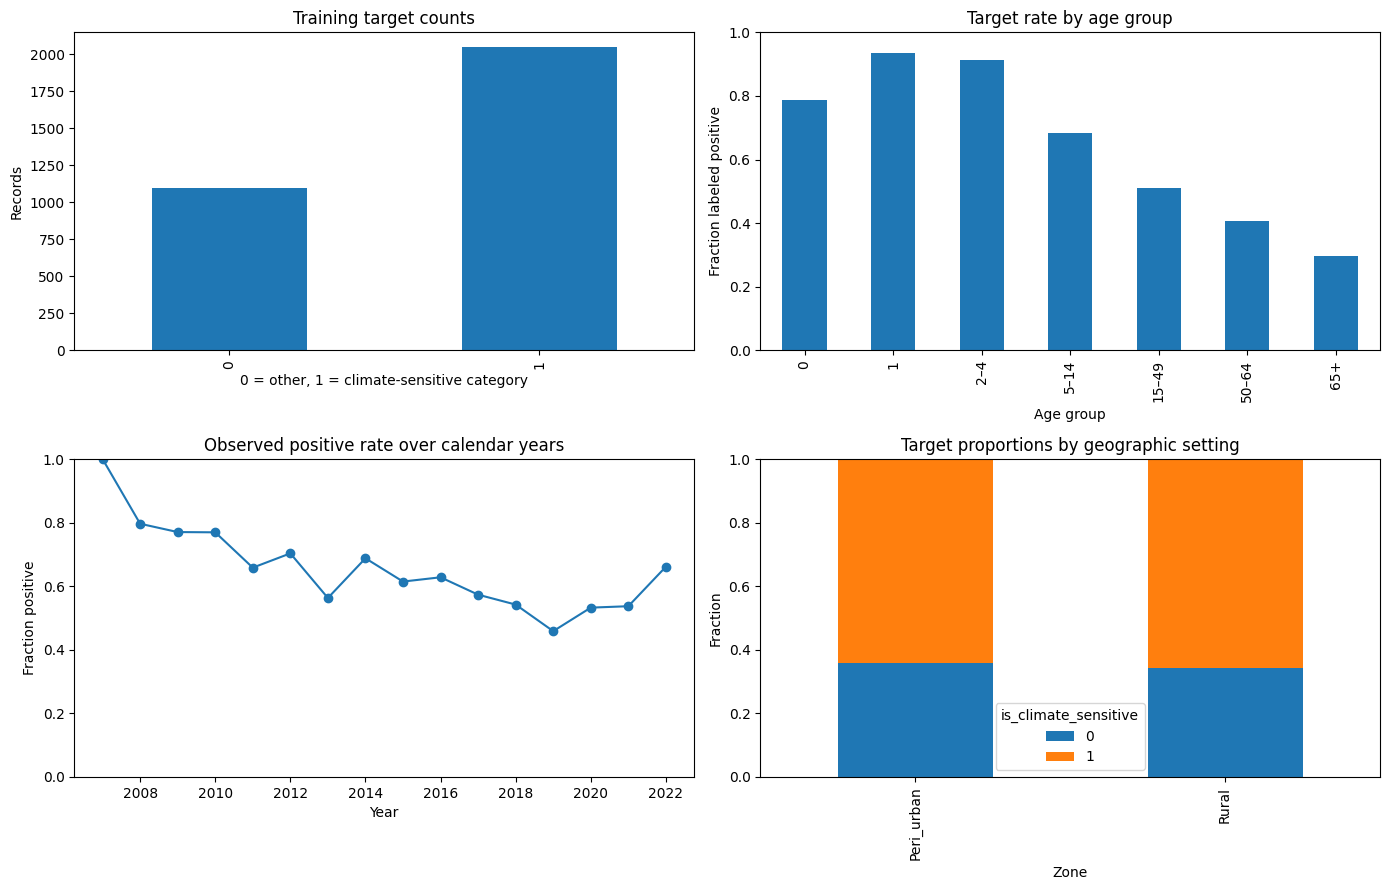

Age group target counts and rates:


,size,mean
age_group,,
0,1112,0.787770
1,281,0.935943
2–4,340,0.911765
5–14,117,0.683761
15–49,525,0.510476
50–64,197,0.406091
65+,574,0.296167


In [4]:
# 4.1 Target distribution and age/year patterns
fig, axs = plt.subplots(2, 2, figsize=(14, 9))
raw_train['is_climate_sensitive'].value_counts().sort_index().plot.bar(ax=axs[0, 0])
axs[0, 0].set(title='Training target counts', xlabel='0 = other, 1 = climate-sensitive category', ylabel='Records')

age_bins = [-.1, .5, 1.5, 4.5, 14.5, 49.5, 64.5, float('inf')]
age_labels = ['0', '1', '2–4', '5–14', '15–49', '50–64', '65+']
train_eda = raw_train.copy()
train_eda['age_group'] = pd.cut(train_eda.age, bins=age_bins, labels=age_labels)
train_eda.groupby('age_group', observed=True).is_climate_sensitive.agg(['mean','count'])['mean'].plot.bar(ax=axs[0, 1])
axs[0, 1].set(title='Target rate by age group', xlabel='Age group', ylabel='Fraction labeled positive', ylim=(0, 1))

train_eda['year'] = pd.to_datetime(train_eda.deathdate).dt.year
annual = train_eda.groupby('year').is_climate_sensitive.agg(['mean','count'])
annual['mean'].plot(ax=axs[1, 0], marker='o')
axs[1, 0].set(title='Observed positive rate over calendar years', xlabel='Year', ylabel='Fraction positive', ylim=(0, 1))

pd.crosstab(raw_train.zone, raw_train.is_climate_sensitive, normalize='index').plot.bar(stacked=True, ax=axs[1, 1])
axs[1, 1].set(title='Target proportions by geographic setting', xlabel='Zone', ylabel='Fraction', ylim=(0, 1))
plt.tight_layout(); plt.savefig(FIG_DIR / 'eda_target_demographic.png', dpi=130); plt.show()

print('Age group target counts and rates:')
display(train_eda.groupby('age_group', observed=True).is_climate_sensitive.agg(['size', 'mean']))

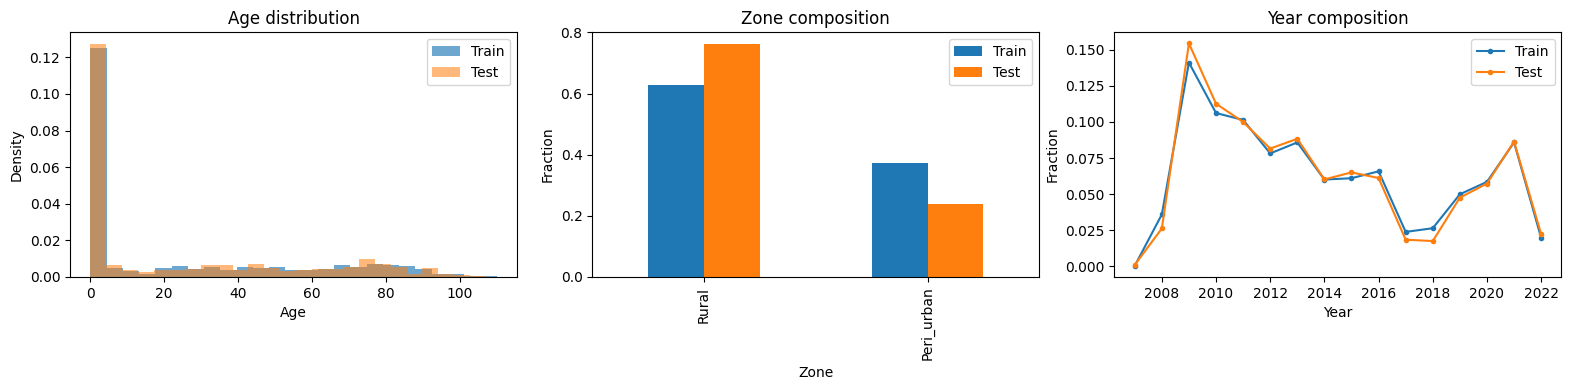

,Train missing,Test missing
ID,0.0,0.0
zone,0.0,0.0
gender,0.0,0.0
deathdate,0.0,0.0
age,0.0,0.0
avg_temperature,0.0,0.0
max_temperature,0.0,0.0
min_temperature,0.0,0.0
precipitation,0.0,0.0
latitude,0.0,0.0


In [5]:
# 4.2 Train-versus-test covariate shift and missingness
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].hist(raw_train.age.dropna(), bins=25, alpha=.65, density=True, label='Train')
axes[0].hist(raw_test.age.dropna(), bins=25, alpha=.55, density=True, label='Test')
axes[0].set(title='Age distribution', xlabel='Age', ylabel='Density'); axes[0].legend()

zone_compare = pd.concat([
    raw_train.zone.value_counts(normalize=True).rename('Train'),
    raw_test.zone.value_counts(normalize=True).rename('Test')], axis=1).fillna(0)
zone_compare.plot.bar(ax=axes[1]); axes[1].set(title='Zone composition', xlabel='Zone', ylabel='Fraction')

train_year = pd.to_datetime(raw_train.deathdate).dt.year.value_counts(normalize=True).sort_index()
test_year = pd.to_datetime(raw_test.deathdate).dt.year.value_counts(normalize=True).sort_index()
axes[2].plot(train_year.index, train_year.values, marker='.', label='Train')
axes[2].plot(test_year.index, test_year.values, marker='.', label='Test')
axes[2].set(title='Year composition', xlabel='Year', ylabel='Fraction'); axes[2].legend()
plt.tight_layout(); plt.savefig(FIG_DIR / 'eda_train_test_shift.png', dpi=130); plt.show()

display(pd.concat([raw_train.isna().mean().rename('Train missing'),
                   raw_test.isna().mean().rename('Test missing')],axis=1).fillna(0))

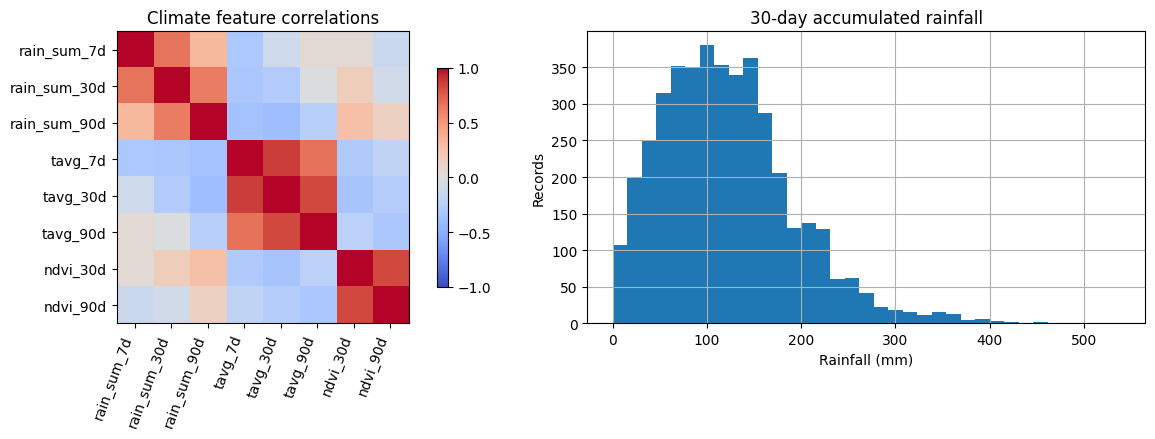

Constant columns in climate file: ['hot_days_30d']


In [6]:
# 4.3 Environmental table exploratory analysis (before merge)
weather_cols = [c for c in ['rain_sum_7d', 'rain_sum_30d', 'rain_sum_90d',
                            'tavg_7d', 'tavg_30d', 'tavg_90d',
                            'ndvi_30d', 'ndvi_90d'] if c in raw_climate.columns]
fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))
corr = raw_climate[weather_cols].corr()
im = axs[0].imshow(corr, vmin=-1, vmax=1, cmap='coolwarm')
axs[0].set_xticks(range(len(weather_cols)), weather_cols, rotation=70, ha='right')
axs[0].set_yticks(range(len(weather_cols)), weather_cols)
axs[0].set_title('Climate feature correlations'); fig.colorbar(im, ax=axs[0], shrink=.75)
raw_climate['rain_sum_30d'].hist(bins=35, ax=axs[1]); axs[1].set(title='30-day accumulated rainfall', xlabel='Rainfall (mm)', ylabel='Records')
plt.tight_layout(); plt.savefig(FIG_DIR/'eda_climate.png', dpi=130); plt.show()
print('Constant columns in climate file:', [c for c in raw_climate if raw_climate[c].nunique(dropna=False) == 1])

## 5. Exact historical data cleaning

The following code is a **documented adaptation of the recovered original `climate_challenge/cleaning/clean_data.py`**. I verified that executing the original script reproduces the saved cleaned CSVs exactly. This notebook applies the same operations using whichever raw-data folder you uploaded.

| Step | Purpose | Treatment |
|---|---|---|
| Validate | Check IDs, allowed categories, dates, ages and coordinates | Fail on unexpected input rather than quietly dropping rows |
| Normalize text | Unicode/whitespace normalization for ID, zone, gender, location | Keep source measurements unchanged |
| Location groups | Lowercase location keys; consolidate **one confirmed alias** with identical coordinates | Preserve original `location` and original latitude/longitude |
| Climate join | One-to-one merge on `(ID, deathdate)` | Require full matching and preserved row order |
| Audit flags | Age zero, possible age heaping, duplicate profiles, multiple location coordinates, distance from train median | Diagnostic columns only, not model features |
| Constant removal | Remove `hot_days_30d`, which is zero on every row | Other climate variables stay in the clean dataset |
| Export | Write cleaned train/test and manifest | No row, label, age, coordinate or weather value edits |

**Age zero is not recoded as missing or infancy by this cleaning process.** The data dictionary does not resolve its meaning. Distance-to-center flags are computed for **auditing only**; because they involve a training-data-derived reference center, such features must not leak into fold validation.

In [7]:
# 5.1 Normalization and input-level validation
raw_a, raw_b = raw_train.copy(), raw_test.copy()
raw_a['dataset'] = 'train'
raw_b['dataset'] = 'test'
combined = pd.concat([raw_a, raw_b], ignore_index=True)

def normalize_text(value):
    return re.sub(r'\s+', ' ', unicodedata.normalize('NFKC', str(value))).strip()

for col in ['ID', 'zone', 'gender', 'location']:
    combined[col] = combined[col].map(normalize_text)

assert combined.ID.is_unique
assert combined.ID.str.fullmatch(r'ID_[0-9A-F]{8}').all()
assert not set(raw_train.ID) & set(raw_test.ID)
combined['deathdate'] = pd.to_datetime(combined.deathdate, format='%Y-%m-%d', errors='raise').dt.strftime('%Y-%m-%d')
assert set(combined.gender) == {'Female', 'Male'}
assert set(combined.zone) == {'Rural', 'Peri_urban'}
assert combined.age.between(0, 120).all()
assert combined.latitude.between(-90, 90).all()
assert combined.longitude.between(-180, 180).all()
assert set(raw_train.is_climate_sensitive) == {0, 1}
assert combined[combined.dataset == 'train'].is_climate_sensitive.notna().all()
print('Input validation passed:', len(raw_train), 'train +', len(raw_test), 'test rows')

Input validation passed: 3146 train + 1030 test rows


In [8]:
# 5.2 Verified spelling alias and quality flags
combined['location_normalized'] = combined.location.str.casefold()
name1 = ('Brac Uganda Iganga Regional Branch, Bikadho Road, Nkaatu Propeer, '
         'Kasokoso North, Iganga, Eastern Region, Uganda')
name2 = ('Brac Uganda Iganga Regional Branch, Bikadho Road, Nkaatu Propeer, '
         'Kasokoso North, Iganga, Uganda')
for name in [name1, name2]:
    assert name in set(combined.location), f'Missing expected alias: {name}'
assert combined[combined.location.isin([name1,name2])][['latitude','longitude']].drop_duplicates().shape[0] == 1
aliases = {name1.casefold(): name2.casefold()}
combined['location_group'] = combined.location_normalized.replace(aliases)

combined['age_zero_flag'] = combined.age.eq(0).astype(int)
combined['age_multiple_of_five_flag'] = (combined.age.ge(5) & combined.age.mod(5).eq(0)).astype(int)
coord_variants = combined.groupby('location_group')[['latitude','longitude']].nunique().max(axis=1)
combined['location_multiple_coordinates_flag'] = combined.location_group.map(coord_variants.gt(1)).astype(int)

train_center = raw_train[['latitude','longitude']].median().to_numpy()
lat, lon = np.radians(combined.latitude), np.radians(combined.longitude)
la, lo = np.radians(train_center)
combined['distance_to_training_center_km'] = 6371 * 2 * np.arcsin(np.sqrt(
    np.sin((lat - la)/2)**2 + np.cos(lat)*np.cos(la)*np.sin((lon-lo)/2)**2))
combined['far_from_training_center_50km_flag'] = combined.distance_to_training_center_km.gt(50).astype(int)

predictor_keys = [col for col in raw_a.columns if col not in ['ID','is_climate_sensitive','dataset']]
combined['duplicate_predictor_record_flag'] = combined.duplicated(predictor_keys, keep=False).astype(int)
print('Training location names:', raw_train.location.nunique())
print('Training canonical location groups:', combined.loc[combined.dataset.eq('train'), 'location_group'].nunique())

Training location names: 39
Training canonical location groups: 38


In [9]:
# 5.3 One-to-one climate join, physical range checks, audit exports
assert raw_climate.ID.is_unique
assert set(raw_climate.ID) == set(combined.ID)
clean_all = combined.merge(raw_climate, on=['ID','deathdate'], how='left',
                           validate='one_to_one', sort=False)
assert clean_all.ID.equals(combined.ID)
assert clean_all[raw_climate.columns[2:]].notna().all().all()
assert (clean_all.rain_sum_7d <= clean_all.rain_sum_30d + 1e-8).all()
assert (clean_all.rain_sum_30d <= clean_all.rain_sum_90d + 1e-8).all()
assert clean_all.rain_days_30d.between(0,30).all()
assert clean_all.hot_days_30d.between(0,30).all()
assert clean_all.ndvi_30d.between(-1,1).all()
assert clean_all.ndvi_90d.between(-1,1).all()
assert (clean_all.min_temperature <= clean_all.avg_temperature).all()
assert (clean_all.avg_temperature <= clean_all.max_temperature).all()
assert (clean_all.tmin_30d <= clean_all.tavg_30d).all()
assert (clean_all.tavg_30d <= clean_all.tmax_30d).all()

# Historical code removes this constant predictor, but retains others for audit.
assert clean_all.hot_days_30d.nunique() == 1
clean_all = clean_all.drop(columns='hot_days_30d')
flags = [c for c in clean_all.columns if c.endswith('_flag')]
quality_cols = ['ID','dataset','location','location_group','age','deathdate',*flags,
                'distance_to_training_center_km']
clean_all[quality_cols].to_csv(DATA_DIR/'quality_flags.csv', index=False)
clean_all[['location','location_group','latitude','longitude']].drop_duplicates().to_csv(
    DATA_DIR/'location_aliases_and_coordinates.csv', index=False)

train = clean_all[clean_all.dataset.eq('train')].drop(columns='dataset').copy()
test = clean_all[clean_all.dataset.eq('test')].drop(columns=['dataset','is_climate_sensitive']).copy()
train = train.reset_index(drop=True)
test = test.reset_index(drop=True)
train['is_climate_sensitive'] = train.is_climate_sensitive.astype(int)
assert train.ID.tolist() == raw_train.ID.tolist()
assert test.ID.tolist() == raw_test.ID.tolist()
for source, output in [(raw_train,train),(raw_test,test)]:
    for c in source.select_dtypes('number').columns:
        if c != 'is_climate_sensitive':
            assert np.array_equal(source[c].values, output[c].values), f'Source numeric value changed: {c}'
assert np.array_equal(train.is_climate_sensitive.values,raw_train.is_climate_sensitive.values)
assert raw_sample.ID.equals(raw_test.ID)

train.to_csv(DATA_DIR/'train_clean.csv', index=False)
test.to_csv(DATA_DIR/'test_clean.csv', index=False)
raw_sample.to_csv(DATA_DIR/'sample_submission.csv', index=False)
sample = pd.read_csv(DATA_DIR/'sample_submission.csv')

# Bring reference outputs into the new run directory when privately supplied.
# A public GitHub release does not include these files.
for filename in ['reference_submission_v5.csv', 'reference_submission_v16.csv']:
    for folder in [RAW_DIR.parent, RAW_DIR.parent.parent/'data']:
        existing = folder / filename
        if existing.exists():
            import shutil
            shutil.copy2(existing, DATA_DIR / filename)
            break
reference_path = DATA_DIR / 'reference_submission_v5.csv'
reference = pd.read_csv(reference_path) if reference_path.exists() else None

source_weather = ['avg_temperature','max_temperature','min_temperature','precipitation']
shared_daily_weather = combined.groupby('deathdate')[source_weather].nunique().max().eq(1).all()
manifest = {
    'train_rows':len(train), 'test_rows':len(test), 'rows_removed':0,
    'labels_changed':0,'age_values_changed':0,'coordinates_changed':0,'weather_values_changed':0,
    'train_location_names_before':raw_train.location.nunique(),
    'train_location_groups_after':train.location_group.nunique(),
    'confirmed_aliases': aliases,
    'training_coordinate_median_for_audit_only':train_center.tolist(),
    'flags_by_split':clean_all.groupby('dataset')[flags].sum().to_dict(),
    'original_weather_shared_within_date':bool(shared_daily_weather),
    'original_weather_unique_dates':int(combined.deathdate.nunique()),
    'constant_feature_excluded':'hot_days_30d',
    'validation_note':'Group on location_group. Audit flags and ID/text are not model predictors.',
    'input_sha256':{p.name:hashlib.sha256(p.read_bytes()).hexdigest() for p in RAW_DIR.glob('*.csv')},
}
(DATA_DIR/'cleaning_manifest.json').write_text(json.dumps(manifest, indent=2))
print('Cleaned shapes:',train.shape,test.shape)
print('Rows removed:',manifest['rows_removed'], '| Target labels changed:',manifest['labels_changed'])
print('Daily original weather shared for identical dates:',manifest['original_weather_shared_within_date'])

Cleaned shapes: (3146, 36) (1030, 35)
Rows removed: 0 | Target labels changed: 0
Daily original weather shared for identical dates: True


## 6. Cleaning verification and post-cleaning EDA

The original dataset ZIP included its own `train_clean.csv`/`test_clean.csv`. In the **private reproduction archive**, saved historical cleaned files are also available. When present, we assert exact column/data equality after reloading both CSVs; this guards against a misleading claim that the cleaning stage was recreated.

EDA flags are **not automatically discarded as bad records**. In particular, far-away coordinates and zero ages remain untouched without authoritative corrections.

In [10]:
# Check exact-match against previously saved historical cleaned files (optional).
# For the private package, RAW_DIR is data/raw and the references are data/*.csv.
reference_dirs = [RAW_DIR.parent, RAW_DIR.parent/'data', RAW_DIR.parent.parent/'data',
                  RAW_DIR.parent.parent/'climate_challenge'/'cleaning'/'data']
matched_history = False
for candidate in reference_dirs:
    if (candidate/'train_clean.csv').exists() and (candidate/'test_clean.csv').exists():
        saved_train = pd.read_csv(candidate/'train_clean.csv')
        saved_test = pd.read_csv(candidate/'test_clean.csv')
        pd.testing.assert_frame_equal(pd.read_csv(DATA_DIR/'train_clean.csv'),saved_train)
        pd.testing.assert_frame_equal(pd.read_csv(DATA_DIR/'test_clean.csv'),saved_test)
        print('Exact historical cleaning reproduction verified against:',candidate)
        matched_history=True
        break
if not matched_history:
    print('Historical cleaned reference not supplied. Source-value invariants passed.')

print('Audit-flag counts (not rows removed):')
display(clean_all.groupby('dataset')[flags].sum().T)
print('Train locations:',train.location_group.nunique(),
      '| Test locations:',test.location_group.nunique(),
      '| Overlap:',len(set(train.location_group)&set(test.location_group)))
print('No training ID or location text will be used as a predictive feature.')

Exact historical cleaning reproduction verified against: /content/v16_end_to_end_work/uploaded_zip/data
Audit-flag counts (not rows removed):


dataset,test,train
age_zero_flag,355,1112
age_multiple_of_five_flag,154,443
location_multiple_coordinates_flag,90,516
far_from_training_center_50km_flag,307,340
duplicate_predictor_record_flag,0,4


Train locations: 38 | Test locations: 11 | Overlap: 1
No training ID or location text will be used as a predictive feature.


size      mean
age_group period                     
0         2018 onward   492  0.563008
          Before 2018   620  0.966129
1         2018 onward    19  0.842105
          Before 2018   262  0.942748
2–4       2018 onward    37  0.891892
          Before 2018   303  0.914191
5–14      2018 onward    35  0.714286
          Before 2018    82  0.670732
15–49     2018 onward    76  0.302632
          Before 2018   449  0.545657
50–64     2018 onward    26  0.500000
          Before 2018   171  0.391813
65+       2018 onward    71  0.197183
          Before 2018   503  0.310139

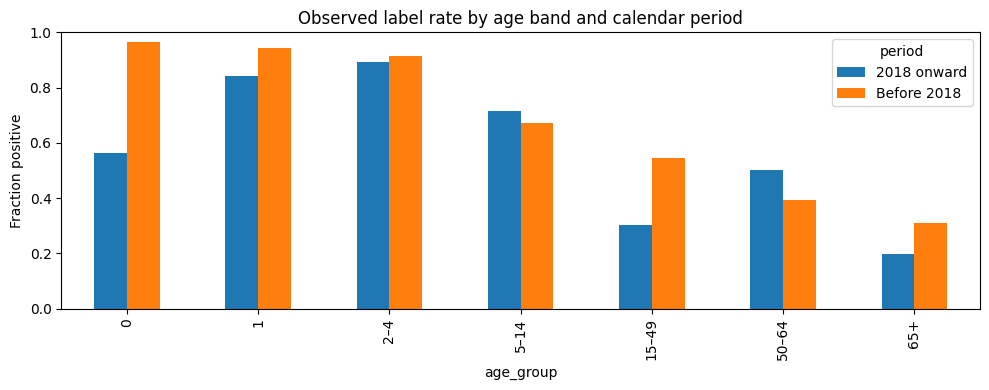

In [11]:
# A further inspection of the strong age-time pattern; descriptive only.
eda = train[['is_climate_sensitive','age','deathdate','zone','gender']].copy()
eda['period'] = np.where(pd.to_datetime(eda.deathdate).dt.year >= 2018,
                         '2018 onward','Before 2018')
eda['age_group'] = pd.cut(eda.age, age_bins, labels=age_labels)
rate_table = eda.groupby(['age_group','period'],observed=True).is_climate_sensitive.agg(['size','mean'])
display(rate_table)
period_rates = eda.groupby(['age_group','period'],observed=True).is_climate_sensitive.mean().unstack()
period_rates.plot.bar(figsize=(10,4), ylim=(0,1), ylabel='Fraction positive',
                      title='Observed label rate by age band and calendar period')
plt.tight_layout();plt.savefig(FIG_DIR/'eda_age_time.png',dpi=130);plt.show()

## 7. Feature engineering for the original V4/V5 foundation

The final V16 lineage uses **deliberately selected** features. The cleaned climate columns are preserved for scientific completeness and alternative experiments, but the *selected* V16 ensemble uses age, gender, rural/peri-urban zone, and death-date transformations.

- **Cyclical month**: sine/cosine represents adjacency of December and January.
- **Age-cohort indicators**: handle distinct mortality-label prevalence by age group.
- **Age × calendar year**: allow different time trends for age bands; an explicit age-zero post-2017 interaction models a possible recording shift without asserting causation.
- **No target encoding** or per-location label averages.
- **No location text, ID, audit flags or target** among the model features.

The next code cell retains the recovered V16 training code rather than rewriting the feature definitions or hyperparameters.

In [12]:
AGECO=['age0','age1','age2to4','cohort_5to14','cohort_15to49','cohort_50to64','cohort_65plus']
AGEYEAR=['age_0_x_year18','age_0_post17','age_0_recent_ramp','age_0_early_ramp']
COHORTYEAR=['age1year','age2to4year','age_5to14year','age_15to49year','age_50to64year','age_65plusyear']
BASE=['age','gender','zone','year','month_sin','month_cos']
AGELITE=['age0','age_le1','age_2to5','age_65p','age_log']
def uniq(*parts): return list(dict.fromkeys(sum(parts, [])))
FEATURES = {
    'cohort_cohortyear':uniq(BASE, AGECO, COHORTYEAR),
    'cohort_all_year':uniq(BASE, AGECO, AGEYEAR, COHORTYEAR),
    'ageyear_flex':uniq(BASE, AGELITE, AGEYEAR, COHORTYEAR),
}
BASE_PARAMS = dict(max_iter=180,learning_rate=.035,max_leaf_nodes=7,
                   l2_regularization=10,min_samples_leaf=20,random_state=42)
DEEP_PARAMS = dict(max_iter=230,learning_rate=.027,max_leaf_nodes=11,
                   l2_regularization=15,min_samples_leaf=30,random_state=42)
SMALL_PARAMS = dict(max_iter=100,learning_rate=.035,max_leaf_nodes=5,
                    min_samples_leaf=25,l2_regularization=20,random_state=42)
EXPERT_DEEP_PARAMS = dict(max_iter=140,learning_rate=.035,max_leaf_nodes=7,
                          min_samples_leaf=20,l2_regularization=20,random_state=42)

def features(d):
    dt=pd.to_datetime(d['deathdate'])
    age=d['age'].to_numpy()
    year=dt.dt.year.to_numpy()
    month=dt.dt.month.to_numpy()
    age0=(age==0).astype(int)
    age1=(age==1).astype(int)
    age2to4=((age>=2)&(age<=4)).astype(int)
    c5to14=((age>=5)&(age<=14)).astype(int)
    c15to49=((age>=15)&(age<=49)).astype(int)
    c50to64=((age>=50)&(age<=64)).astype(int)
    c65=(age>=65).astype(int)
    return pd.DataFrame({
      'age':age,'gender':d['gender'].eq('Female').astype(int).to_numpy(),
      'zone':d['zone'].eq('Peri_urban').astype(int).to_numpy(),
      'year':year,'month_sin':np.sin(2*np.pi*month/12),
      'month_cos':np.cos(2*np.pi*month/12),
      'age0':age0,'age1':age1,'age2to4':age2to4,
      'cohort_5to14':c5to14,'cohort_15to49':c15to49,
      'cohort_50to64':c50to64,'cohort_65plus':c65,
      'age_le1':(age<=1).astype(int),
      'age_2to5':((age>=2)&(age<=5)).astype(int),
      'age_65p':c65,'age_log':np.log1p(age),
      'age_0_x_year18':age0*(year-2018),
      'age_0_post17':age0*(year>=2018),
      'age_0_recent_ramp':age0*np.maximum(year-2016,0),
      'age_0_early_ramp':age0*np.maximum(2018-year,0),
      'age1year':age1*(year-2018),
      'age2to4year':age2to4*(year-2018),
      'age_5to14year':c5to14*(year-2018),
      'age_15to49year':c15to49*(year-2018),
      'age_50to64year':c50to64*(year-2018),
      'age_65plusyear':c65*(year-2018),
    })

def model_predictions(xtrain, ytrain, xtest, age_train, age_test):
    probs=[]
    for feat,par in [('cohort_cohortyear',DEEP_PARAMS),
                     ('cohort_all_year',BASE_PARAMS),
                     ('ageyear_flex',BASE_PARAMS)]:
        cols=FEATURES[feat]
        model=HistGradientBoostingClassifier(**par)
        model.fit(xtrain[cols],ytrain)
        probs.append(model.predict_proba(xtest[cols])[:,1])
    # Distinct age-zero and age<=4 experts, each fitted only on the relevant
    # training age stratum. These are model architectures, not threshold rules.
    cols=FEATURES['cohort_all_year']
    for training_mask,test_mask,par in [
        (age_train==0,age_test==0,SMALL_PARAMS),
        (age_train<=4,age_test<=4,EXPERT_DEEP_PARAMS),
    ]:
        predictions=np.empty(len(xtest),dtype=float)
        for group in (True,False):
            fit_indices=(training_mask==group)
            pred_indices=(test_mask==group)
            if not pred_indices.any():continue
            if np.unique(ytrain[fit_indices]).size<2:
                raise ValueError('Training cohort has only one class')
            model=HistGradientBoostingClassifier(**par)
            model.fit(xtrain.loc[fit_indices,cols],ytrain[fit_indices])
            predictions[pred_indices]=model.predict_proba(xtest.loc[pred_indices,cols])[:,1]
        probs.append(predictions)
    return np.mean(probs,axis=0)

In [13]:
# Inspect design matrix and make leakage boundaries visible.
X_preview = features(train)
print('Base feature matrix:',X_preview.shape)
print('Features used by original V4 specialist ensemble:', sorted(set(sum(FEATURES.values(), []))))
assert not ({'ID','location','location_group','is_climate_sensitive'} & set(X_preview.columns))
display(X_preview.describe().T[['mean','std','min','max']].head(20))

Base feature matrix: (3146, 27)
Features used by original V4 specialist ensemble: ['age', 'age0', 'age1', 'age1year', 'age2to4', 'age2to4year', 'age_0_early_ramp', 'age_0_post17', 'age_0_recent_ramp', 'age_0_x_year18', 'age_15to49year', 'age_2to5', 'age_50to64year', 'age_5to14year', 'age_65p', 'age_65plusyear', 'age_le1', 'age_log', 'cohort_15to49', 'cohort_50to64', 'cohort_5to14', 'cohort_65plus', 'gender', 'month_cos', 'month_sin', 'year', 'zone']


,mean,std,min,max
age,24.243484,31.428833,0.0,110.00000
gender,0.477114,0.499555,0.0,1.00000
zone,0.373172,0.483724,0.0,1.00000
year,2013.834075,4.195894,2007.0,2022.00000
month_sin,0.012856,0.682737,-1.0,1.00000
month_cos,-0.030168,0.730145,-1.0,1.00000
age0,0.353465,0.478121,0.0,1.00000
age1,0.089320,0.285250,0.0,1.00000
age2to4,0.108074,0.310523,0.0,1.00000
cohort_5to14,0.037190,0.189257,0.0,1.00000


## 8. The historical model-development chain

V16 did not start from an isolated logistic regression. It retained the best-performing earlier ensemble and added two complementary smooth classifiers. The code below reproduces each stage with its **historical parameters**, not retrospective tuning.

| Version | Architecture |
|---|---|
| **V4 foundation** | 3 age/cohort HGB models + 2 age-stratified HGB specialists (equal average) |
| **V5** | `0.80 × V4 + 0.20 × shallow HGB` |
| **V13** | `0.85 × V5 + 0.15 × tuned shallow HGB` |
| **V14** | `0.90 × V13 + 0.10 × ranking-focused HGB` |
| **V15** | For ages ≥15 only: `0.95 × V14 + 0.05 × lightly weighted adult HGB`; retain V14 for younger ages |
| **V16** | `0.40 × V15 + 0.40 × smooth age–time logistic + 0.20 × rich age–time logistic` |

All binary submissions follow `TargetF1 = (TargetRAUC >= 0.5)`. The threshold is mandated by the competition and is not optimized.

In [14]:
SHALLOW_V5_PARAMS = dict(max_iter=280, learning_rate=0.025, max_leaf_nodes=5,
                         l2_regularization=40, min_samples_leaf=25, random_state=42)

def shallow_features(df):
    X = features(df).copy()
    X['day_of_year'] = pd.to_datetime(df['deathdate']).dt.dayofyear.to_numpy()
    return X

def predict_v5(train_df, test_df):
    """Fit exact V5 on the supplied training rows; return probabilities and components."""
    y = train_df['is_climate_sensitive'].to_numpy().astype(int)
    age_train = train_df['age'].to_numpy()
    age_test = test_df['age'].to_numpy()
    X4train = features(train_df)
    X4test = features(test_df)
    p4 = model_predictions(X4train, y, X4test, age_train, age_test)
    shallow = HistGradientBoostingClassifier(**SHALLOW_V5_PARAMS)
    shallow.fit(shallow_features(train_df), y)
    p_shallow = shallow.predict_proba(shallow_features(test_df))[:, 1]
    p_v5 = 0.8*p4 + 0.2*p_shallow
    assert np.isfinite(p_v5).all() and ((p_v5 >= 0) & (p_v5 <= 1)).all()
    return p_v5, p4, p_shallow

### V5 fit and exact reference check

V5 remains the anchor of the entire modeling history. If a saved reference submission exists, this step checks numerical identity. Without it, the pipeline still makes a valid CSV and performs consistency checks.

In [15]:
v5_probs, v4_probs, shallow_probs = predict_v5(train, test)
submission_v5 = sample[['ID']].copy()
submission_v5['TargetF1'] = (v5_probs >= 0.5).astype(int)
submission_v5['TargetRAUC'] = v5_probs
if reference is not None:
    max_abs_error = float(np.abs(submission_v5.TargetRAUC - reference.TargetRAUC).max())
    label_diffs = int((submission_v5.TargetF1 != reference.TargetF1).sum())
    assert max_abs_error < 1e-10, f'V5 reproduction mismatch: {max_abs_error}'
    assert label_diffs == 0, f'V5 binary labels changed: {label_diffs}'
    print('V5 exact-reference check passed:', max_abs_error, 'maximum probability difference')
else:
    print('V5 reference not present. Skipping optional V5 exact-match test.')
assert submission_v5.TargetF1.equals((submission_v5.TargetRAUC >= 0.5).astype(int))
submission_v5.to_csv(OUTPUT_DIR/'V5_reconstructed.csv', index=False, float_format='%.12f')
print('V5 positive predictions:', int(submission_v5.TargetF1.sum()))

V5 reference not present. Skipping optional V5 exact-match test.
V5 positive predictions: 725


### Local metrics and geographic validation

The competition weights **F1 at 60%** and **ROC-AUC at 40%**. Repeated `StratifiedGroupKFold` assigns whole canonical locations to either training or validation in a given fold. This avoids leakage across duplicate location names, but the finite dataset and marked test-distribution shift mean local performance may not predict Zindi performance.

For a fast normal run, both CV switches are `False`. Turn them on only when benchmarking or improving the model. Grouping is done *before* fitting any estimator or age-time transform that learns labels.

In [16]:
def evaluate_probabilities(y, p):
    f = f1_score(y, (p >= 0.5).astype(int), zero_division=0)
    a = roc_auc_score(y, p)
    return dict(weighted=0.6*f+0.4*a, f1=f, auc=a,
                brier=brier_score_loss(y, p), positive_predictions=int((p >= 0.5).sum()))

def run_v5_cv(df, seeds=SEEDS):
    y = df['is_climate_sensitive'].to_numpy().astype(int)
    groups = df['location_group'].astype(str).to_numpy()
    metrics = []
    oofs = []
    for seed in seeds:
        p = np.full(len(df), np.nan)
        cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=seed)
        for fold, (tr, va) in enumerate(cv.split(df, y, groups), start=1):
            assert set(groups[tr]).isdisjoint(groups[va])
            pred, _, _ = predict_v5(df.iloc[tr].reset_index(drop=True),
                                    df.iloc[va].reset_index(drop=True))
            p[va] = pred
        assert np.isfinite(p).all()
        metrics.append(dict(seed=seed, **evaluate_probabilities(y, p)))
        oofs.append(pd.DataFrame({'ID':df['ID'].to_numpy(), 'seed':seed,
                                  'target':y, 'prediction':p, 'location_group':groups}))
    return pd.DataFrame(metrics), pd.concat(oofs, ignore_index=True)

In [17]:
if RUN_VALIDATION:
    v5_cv, v5_oof = run_v5_cv(train, seeds=SEEDS)
    display(v5_cv)
    v5_cv.to_csv(OUTPUT_DIR/'v5_group_cv_metrics.csv', index=False)
    v5_oof.to_csv(OUTPUT_DIR/'v5_group_cv_oof.csv', index=False)

### V13: tuned shallow challenger

This parameter set was selected during earlier experiments and should be described as **historically tuned**, not an unbiased generalization test. The blend was chosen to improve ranking with minimal binary-label changes.

In [18]:
from sklearn.ensemble import HistGradientBoostingClassifier
V13_CHALLENGER_PARAMS = dict(
    max_iter=180, learning_rate=0.03535762330758312,
    max_leaf_nodes=9, max_depth=4,
    l2_regularization=6.453866756026858,
    min_samples_leaf=35, random_state=42, early_stopping=False
)
V13_BLEND_WEIGHT = 0.15
v13_model = HistGradientBoostingClassifier(**V13_CHALLENGER_PARAMS)
v13_model.fit(shallow_features(train), train["is_climate_sensitive"].astype(int))
v13_challenger_prob = v13_model.predict_proba(shallow_features(test))[:, 1]
v13_prob = (1 - V13_BLEND_WEIGHT) * v5_probs + V13_BLEND_WEIGHT * v13_challenger_prob
v13_sub = sample[["ID"]].copy()
v13_sub["TargetF1"] = (v13_prob >= 0.5).astype(int)
v13_sub["TargetRAUC"] = v13_prob
assert v13_sub["ID"].equals(test["ID"])
assert ((v13_prob >= 0) & (v13_prob <= 1)).all()
assert v13_sub["TargetF1"].equals((v13_sub["TargetRAUC"] >= 0.5).astype(int))
output_v13 = OUTPUT_DIR / "V13.csv"
v13_sub.to_csv(output_v13, index=False, float_format="%.12f")
print("Saved V13 candidate:", output_v13)
print("Label changes vs V5:", (v13_sub["TargetF1"] != submission_v5["TargetF1"]).sum())
print("Validation: V5 0.821927, V13 0.822414 (three geographic splits; not Zindi)")

Saved V13 candidate: /content/v16_end_to_end_work/outputs/V13.csv
Label changes vs V5: 4
Validation: V5 0.821927, V13 0.822414 (three geographic splits; not Zindi)


### V14: stronger probability ranking

V14 adds a heavily regularized slow-learning gradient-boosting model; this improved public ROC-AUC while retaining nearly the same F1. The labeled training rows used for the final fit do not enter any holdout evaluation.

In [19]:
V14_RANKING_PARAMS = dict(
    max_iter=300,
    learning_rate=0.011294737914661061,
    max_leaf_nodes=9,
    max_depth=5,
    l2_regularization=88.2993464752687,
    min_samples_leaf=25,
    random_state=42,
    early_stopping=False,
)
V14_RANKING_WEIGHT = 0.10
v14_rank_model = HistGradientBoostingClassifier(**V14_RANKING_PARAMS)
v14_rank_model.fit(shallow_features(train), train['is_climate_sensitive'].astype(int))
v14_rank_probs = v14_rank_model.predict_proba(shallow_features(test))[:, 1]
v14_probs = (1 - V14_RANKING_WEIGHT) * v13_prob + V14_RANKING_WEIGHT * v14_rank_probs
v14_submission = sample[['ID']].copy()
v14_submission['TargetF1'] = (v14_probs >= 0.5).astype(int)
v14_submission['TargetRAUC'] = v14_probs
assert v14_submission['ID'].equals(test['ID'])
assert np.isfinite(v14_probs).all() and (v14_probs >= 0).all() and (v14_probs <= 1).all()
assert v14_submission['TargetF1'].equals((v14_submission['TargetRAUC'] >= 0.5).astype(int))
v14_path = OUTPUT_DIR / 'V14.csv'
v14_submission.to_csv(v14_path, index=False, float_format='%.12f')
print('V14 CSV:', v14_path)
print('V13 positives:', v13_sub.TargetF1.sum(), 'V14 positives:', v14_submission.TargetF1.sum())
print('Binary label changes versus V13:', (v14_submission.TargetF1 != v13_sub.TargetF1).sum())

V14 CSV: /content/v16_end_to_end_work/outputs/V14.csv
V13 positives: 725 V14 positives: 726
Binary label changes versus V13: 7


### V15: a cost-sensitive specialist for adults

The age-15+ specialist mildly increases positive-class example weights by 10% **during training only**. This is not a post-hoc threshold adjustment. The final V15 blend leaves younger records on their V14 predictions.

In [20]:
# F1-focused specialist (all hyperparameters fixed from V15 experiments)
V15_ADULT_PARAMS = dict(
    max_iter=260, learning_rate=0.025, max_leaf_nodes=7,
    l2_regularization=80, min_samples_leaf=15,
    random_state=42, early_stopping=False,
)
V15_SPECIALIST_WEIGHT = 0.05
adult_train_mask = (train['age'].to_numpy() >= 15)
adult_test_mask = (test['age'].to_numpy() >= 15)
y_full = train['is_climate_sensitive'].to_numpy().astype(int)
model_v15 = HistGradientBoostingClassifier(**V15_ADULT_PARAMS)
model_v15.fit(shallow_features(train).loc[adult_train_mask],
              y_full[adult_train_mask],
              sample_weight=np.where(y_full[adult_train_mask] == 1, 1.10, 1.00))
adult_test_pred = model_v15.predict_proba(
    shallow_features(test).loc[adult_test_mask])[:, 1]
v15_probs = v14_probs.copy()
v15_probs[adult_test_mask] = (
    (1.0 - V15_SPECIALIST_WEIGHT) * v14_probs[adult_test_mask]
    + V15_SPECIALIST_WEIGHT * adult_test_pred
)
v15_submission = sample[['ID']].copy()
v15_submission['TargetRAUC'] = v15_probs
v15_submission['TargetF1'] = (v15_probs >= 0.5).astype(int)
v15_submission = v15_submission[['ID', 'TargetF1', 'TargetRAUC']]
assert v15_submission.ID.equals(test.ID)
assert v15_submission.TargetF1.equals((v15_submission.TargetRAUC >= 0.5).astype(int))
assert np.isfinite(v15_probs).all() and np.all((v15_probs >= 0) & (v15_probs <= 1))
v15_output = OUTPUT_DIR/'V15.csv'
v15_submission.to_csv(v15_output, index=False, float_format='%.12f')
print('Saved:', v15_output)
print('Changed labels versus V14:', int((v15_submission.TargetF1 != v14_submission.TargetF1).sum()))
print('Positive predictions:', int(v15_submission.TargetF1.sum()))

Saved: /content/v16_end_to_end_work/outputs/V15.csv
Changed labels versus V14: 3
Positive predictions: 725


## 9. V16 feature engineering: nonlinear age and time

Two logistic models generate **fixed** nonlinear bases (not learned from the target before cross-validation):

- **Smooth age–time model:** one-hot age cohorts, gender/zone interactions, sine/cosine month, age-specific year trends, Gaussian radial basis functions centered every two years from 2008 to 2022. `C=0.004` implies strong L2 regularization.
- **Rich age model:** the same basis plus smoothed steps centered at 2017, 2017.5, 2018, 2019, and smooth functions of log-age at fixed age knots. `C=0.25` means weaker regularization than the first model.

The builder supports exploratory climate variables, but **`weather=False` for the historical final V16 fit**. Do not claim this V16 submission used NASA POWER humidity variables; they were evaluated in separate experiments, not included in the chosen model.

In [21]:
# New V16 architecture. All feature knots/age bands are fixed a priori.
from sklearn.linear_model import LogisticRegression
def build(d,form='cohort_rbfs',weather=False):
 date=pd.to_datetime(d.deathdate);a=d.age.to_numpy();year=(date.dt.year+(date.dt.dayofyear-1)/365.25).to_numpy(); month=date.dt.month.to_numpy()
 cohort=np.digitize(a, [0.5,1.5,4.5,14.5,49.5,64.5]); co=np.eye(7)[cohort]
 sex=d.gender.eq('Female').to_numpy().astype(float); urban=d.zone.eq('Peri_urban').to_numpy().astype(float)
 X=[co,sex[:,None],urban[:,None],(sex[:,None]*co),(urban[:,None]*co)]
 # smooth 7 age bands with 2017 temporal discontinuity and smoothed after-effects
 for label,feat in [('year_linear',(year-2016)[:,None]/8),('month_sin',np.sin(2*np.pi*month/12)[:,None]),('month_cos',np.cos(2*np.pi*month/12)[:,None])]:
  X.append(feat);X.append(co*feat)
 # smooth year RBF by age bin; 2017 abrupt break included
 for yc in np.arange(2008,2023,2.0):
  r=np.exp(-.5*((year-yc)/2.0)**2)
  X.append(co*r[:,None])
 if form in ('cohort_break','cohort_rich','cohort_weather'):
  for s in (2017.0,2017.5,2018.0,2019.0):
   r=1/(1+np.exp(-np.clip((year-s)*4,-30,30)))
   X.append(co*r[:,None])
 if form in ('cohort_rich','cohort_weather'):
  # age splines via log distance at fixed points (nonlinear smooth age), plus adult 1-yr age trend
  for ac in [0,1,2,5,15,30,45,60,75,90]:
   v=np.exp(-.5*((np.log1p(a)-np.log1p(ac))/.5)**2)
   X.append(v[:,None]);X.append((v*urban)[:,None]);X.append((v*sex)[:,None])
  # age x time shifts for adult and children
  X.append(((a>=15) & (a<=49))[:,None]*((year-2016)/6)[:,None])
 if weather or form=='cohort_weather':
  # Predefined coarse rainfall / temperature anomaly stats, standardized using fixed real ranges
  rain=d.rain_sum_30d.to_numpy()/150
  anom=np.clip((d.tavg_7d-d.tavg_90d).to_numpy()/3,-3,3)
  ndvi=(d.ndvi_30d-d.ndvi_90d).to_numpy()*10
  re=(d.rain_sum_7d.to_numpy()/7-d.rain_sum_90d.to_numpy()/90)/10
  for z in (rain,anom,ndvi,re):
   z=np.nan_to_num(z,nan=0,posinf=0,neginf=0)
   X.append(z[:,None]);X.append(co*z[:,None])
 z=np.column_stack(X).astype(np.float64)
 return z


V16_WEIGHTS = {'v15': 0.40, 'smooth_time': 0.40, 'rich_age': 0.20}
Y_FULL=train['is_climate_sensitive'].astype(int).to_numpy()

smooth_train=build(train,'cohort_rbfs')
smooth_test=build(test,'cohort_rbfs')
smooth_model=LogisticRegression(C=0.004,solver='lbfgs',max_iter=700)
smooth_model.fit(smooth_train,Y_FULL)
smooth_pred=smooth_model.predict_proba(smooth_test)[:,1]

rich_train=build(train,'cohort_rich')
rich_test=build(test,'cohort_rich')
rich_model=LogisticRegression(C=0.25,solver='lbfgs',max_iter=700)
rich_model.fit(rich_train,Y_FULL)
rich_pred=rich_model.predict_proba(rich_test)[:,1]

v16_probability=(0.40*v15_probs + 0.40*smooth_pred + 0.20*rich_pred)
submission_v16=sample[['ID']].copy()
submission_v16['TargetF1']=(v16_probability>=0.5).astype(int)
submission_v16['TargetRAUC']=v16_probability
assert submission_v16.ID.equals(test.ID)
assert submission_v16.TargetF1.equals((submission_v16.TargetRAUC>=0.5).astype(int))
assert np.isfinite(v16_probability).all() and ((v16_probability>=0)&(v16_probability<=1)).all()
assert submission_v16.TargetF1.sum()==775
outpath=OUTPUT_DIR/'V16.csv'
submission_v16.to_csv(outpath,index=False,float_format='%.12f')
print('Wrote:',outpath,'positive predictions:',int(submission_v16.TargetF1.sum()))
print('Changed binary labels from V15:',int((submission_v16.TargetF1!=v15_submission.TargetF1).sum()))

Wrote: /content/v16_end_to_end_work/outputs/V16.csv positive predictions: 775
Changed binary labels from V15: 60


## 10. Verify and export the V16 submission

The CSV must contain exactly `ID, TargetF1, TargetRAUC`, preserve test row order and use a fixed **0.5 threshold**. The historical V16 had **775 positive predictions** and changed 60 binary labels relative to V15. The saved V16 reference CSV, when supplied in the private package, is used to assert exact reproduction.

In [22]:
assert list(submission_v16.columns) == ['ID', 'TargetF1', 'TargetRAUC']
assert len(submission_v16) == len(test)
assert submission_v16.ID.equals(sample.ID)
assert submission_v16.TargetF1.isin([0, 1]).all()
assert submission_v16.TargetRAUC.between(0, 1).all()
assert submission_v16.TargetF1.equals((submission_v16.TargetRAUC >= 0.5).astype(int))

v16_reference_path = DATA_DIR/'reference_submission_v16.csv'
if v16_reference_path.exists():
    v16_reference = pd.read_csv(v16_reference_path)
    assert v16_reference.ID.equals(submission_v16.ID)
    diff = np.max(np.abs(v16_reference.TargetRAUC.to_numpy() - submission_v16.TargetRAUC.to_numpy()))
    changed = int((v16_reference.TargetF1 != submission_v16.TargetF1).sum())
    assert diff < 1e-10 and changed == 0
    print('Exact V16 reproduction verified. Maximum absolute probability error:', diff)
else:
    print('Exact V16 reference omitted. Structure and threshold checks passed.')

print('Submission saved:', outpath)
print('V15 positive predictions:', int(v15_submission.TargetF1.sum()))
print('V16 positive predictions:', int(submission_v16.TargetF1.sum()))
print('Binary predictions changed from V15:',
      int((v15_submission.TargetF1 != submission_v16.TargetF1).sum()))
display(submission_v16.head())

Exact V16 reference omitted. Structure and threshold checks passed.
Submission saved: /content/v16_end_to_end_work/outputs/V16.csv
V15 positive predictions: 725
V16 positive predictions: 775
Binary predictions changed from V15: 60


,ID,TargetF1,TargetRAUC
0,ID_E760D84B,1,0.552011
1,ID_6EDEA907,1,0.658406
2,ID_B9FFC8D8,1,0.527149
3,ID_74C6C94E,0,0.481861
4,ID_0E02825D,1,0.716219


## 11. Public leaderboard: report the actual result

Competition rank (63/1,601) was reported by the project owner and is not verified within the files. It should not be conflated with the public score of this exact V16 run. **V16 was not the highest-scoring experiment:** it improved grouped local validation but reduced F1 on Zindi compared with V15. This is a substantive finding, not a failure to hide.

In [23]:
public_scores = pd.DataFrame([
    ('V5', 0.840764447, 0.836879432, 0.846591970),
    ('V13', 0.841324671, 0.836879432, 0.847992530),
    ('V14', 0.841436716, 0.836879432, 0.848272642),
    ('V15', 0.841567435, 0.836879432, 0.848599439),
    ('V16', 0.835233566, 0.826789838, 0.847899159),
], columns=['Version','Overall','F1','ROC-AUC'])
public_scores['Recalculated'] = 0.6*public_scores.F1 + 0.4*public_scores['ROC-AUC']
assert np.allclose(public_scores.Overall, public_scores.Recalculated, atol=1e-9)
display(public_scores[['Version','Overall','F1','ROC-AUC']])
print('Best confirmed public version:', public_scores.loc[public_scores.Overall.idxmax(),'Version'])

,Version,Overall,F1,ROC-AUC
0,V5,0.840764,0.836879,0.846592
1,V13,0.841325,0.836879,0.847993
2,V14,0.841437,0.836879,0.848273
3,V15,0.841567,0.836879,0.848599
4,V16,0.835234,0.826790,0.847899


Best confirmed public version: V15


## 12. Optional, leakage-safe V16 grouped CV

The function below recomputes *every* model **inside** each fold, then ensembles fold-specific probabilities. This is expensive. The saved public score should never be described as a CV score, and CV alone should not be used to infer hidden-test generalization.

In [24]:
def predict_v16_for_fold(fit_df, holdout_df):
    """Leakage-safe predictions. Every fit uses fit_df only."""
    y_fit = fit_df.is_climate_sensitive.astype(int).to_numpy()
    x_fit, x_hold = shallow_features(fit_df), shallow_features(holdout_df)

    p5 = predict_v5(fit_df, holdout_df)[0]
    p13extra = HistGradientBoostingClassifier(**V13_CHALLENGER_PARAMS).fit(
        x_fit, y_fit).predict_proba(x_hold)[:, 1]
    p13 = .85 * p5 + .15 * p13extra
    p14extra = HistGradientBoostingClassifier(**V14_RANKING_PARAMS).fit(
        x_fit, y_fit).predict_proba(x_hold)[:, 1]
    p14 = .90 * p13 + .10 * p14extra

    p15 = p14.copy()
    adult_fit = fit_df.age.to_numpy() >= 15
    adult_hold = holdout_df.age.to_numpy() >= 15
    if adult_hold.any():
        adult_labels = y_fit[adult_fit]
        adult_model = HistGradientBoostingClassifier(**V15_ADULT_PARAMS)
        adult_model.fit(x_fit.loc[adult_fit], adult_labels,
                        sample_weight=np.where(adult_labels == 1, 1.10, 1.0))
        adult_p = adult_model.predict_proba(x_hold.loc[adult_hold])[:, 1]
        p15[adult_hold] = .95*p14[adult_hold] + .05*adult_p

    smooth = LogisticRegression(C=.004, solver='lbfgs', max_iter=700)
    smooth.fit(build(fit_df, 'cohort_rbfs'), y_fit)
    p_smooth = smooth.predict_proba(build(holdout_df, 'cohort_rbfs'))[:, 1]
    rich = LogisticRegression(C=.25, solver='lbfgs', max_iter=700)
    rich.fit(build(fit_df, 'cohort_rich'), y_fit)
    p_rich = rich.predict_proba(build(holdout_df, 'cohort_rich'))[:, 1]
    return .40*p15 + .40*p_smooth + .20*p_rich

if RUN_V16_VALIDATION:
    val_results, val_predictions = [], []
    y = train.is_climate_sensitive.astype(int).to_numpy()
    groups = train.location_group.astype(str).to_numpy()
    for seed in SEEDS:
        oof = np.full(len(train), np.nan)
        cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=seed)
        for fold, (fit_idx, val_idx) in enumerate(cv.split(train, y, groups), start=1):
            assert set(groups[fit_idx]).isdisjoint(groups[val_idx])
            oof[val_idx] = predict_v16_for_fold(
                train.iloc[fit_idx].reset_index(drop=True),
                train.iloc[val_idx].reset_index(drop=True))
        assert np.isfinite(oof).all()
        val_results.append({'seed':seed, **evaluate_probabilities(y, oof)})
        val_predictions.append(pd.DataFrame({'ID':train.ID, 'seed':seed,
                                             'target':y, 'prediction':oof}))
    cv_results = pd.DataFrame(val_results)
    cv_oof = pd.concat(val_predictions, ignore_index=True)
    display(cv_results)
    cv_results.to_csv(OUTPUT_DIR/'v16_group_cv_metrics.csv', index=False)
    cv_oof.to_csv(OUTPUT_DIR/'v16_group_cv_oof.csv', index=False)

## 13. Error analysis and discussion

The final notebook can compare the 0.5 binary outputs with V15 and visualize the probability distribution. Test labels are hidden, so we **cannot** identify which particular test records are mistakes. Any classification analysis of labeled rows should use out-of-fold predictions, **not** model outputs fitted on those same rows.

V15 positive test predictions: 725
V16 positive test predictions: 775
Binary changes: 60


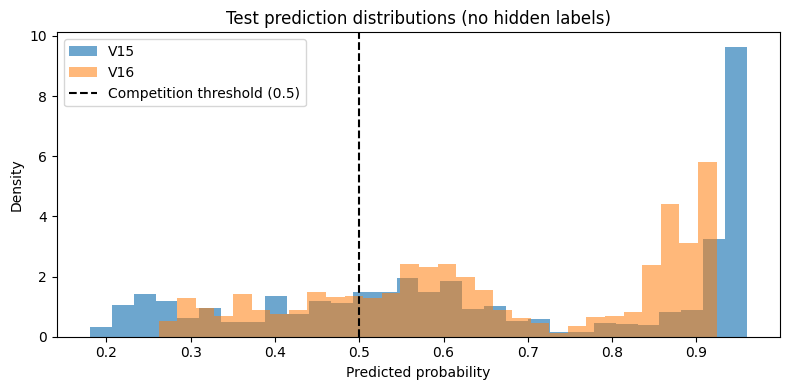

Change counts by age group:


,sum,size
age_group,,
0,13,355
1,0,89
2–4,0,117
5–14,3,48
15–49,24,180
50–64,9,59
65+,11,182


In [25]:
# Unlabeled test-set diagnostics: these are NOT accuracy statistics.
changes = (v15_submission.TargetF1 != submission_v16.TargetF1)
print('V15 positive test predictions:',int(v15_submission.TargetF1.sum()))
print('V16 positive test predictions:',int(submission_v16.TargetF1.sum()))
print('Binary changes:',int(changes.sum()))
fig, ax = plt.subplots(figsize=(8,4))
ax.hist(v15_probs, bins=30, alpha=.65, label='V15', density=True)
ax.hist(v16_probability, bins=30, alpha=.55, label='V16', density=True)
ax.axvline(.5,linestyle='--',color='black',label='Competition threshold (0.5)')
ax.set(title='Test prediction distributions (no hidden labels)',
       xlabel='Predicted probability',ylabel='Density')
ax.legend();plt.tight_layout();plt.savefig(FIG_DIR/'predictions_v15_v16.png',dpi=130);plt.show()
print('Change counts by age group:')
display(pd.DataFrame({'age_group':pd.cut(test.age, age_bins,labels=age_labels),
                      'changed':changes.to_numpy()}).groupby('age_group',observed=True)['changed'].agg(['sum','size']))

## 14. Conclusions, limitations and next steps

**What we learned**

- Data cleaning improved trustworthiness and reproducibility but **did not** change the labels or delete records.
- Age, calendar time, sex and rural/peri-urban zone dominated the historical V16's **selected** features. The presence of supplied environmental measurements does not mean every selected model uses them.
- The smooth age–time models improved repeated location-held-out validation, but the public V16 score was **worse than V15**. Geographic shift, age-zero ambiguity, few location groups and validation selection effects likely matter.
- A model predicting climate-sensitive *categories* cannot by itself establish a climate exposure causing death.

**Recommended future work:** independently verify label-construction rules and age-zero semantics; audit location mapping; hold out entire spatial grids and time eras; evaluate calibration separately from ranking; use legal/public climate data for new lagged exposure indicators only when they add robust out-of-area predictive value.

**Reproduce:** the private ZIP includes raw source data and reference submissions. The public GitHub ZIP intentionally does not. `outputs/V16.csv` is recreated only when all earlier modeling cells execute successfully.